# Sales Forecast

Forecast daily units sold (`Quantity`) and sales (`Total_Amount`) for the 4 weeks after the data ends (14 Feb 2026). Each model is scored on weeks it hasn't seen, and compared against simple averages, so we only use a more complex model if it actually does better.

In [1]:
import sys
import logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from prophet import Prophet

sys.path.append('..')  #make src/ importable from notebooks/
from src.data import load_merged, daily_series

logging.getLogger('cmdstanpy').disabled = True  #hide Prophet's fitting messages
%matplotlib inline

In [2]:
df = load_merged()
df_Quantity = daily_series(df, 'Quantity')  #one row per calendar day, 0 on days with no sales
df_Sales = daily_series(df, 'Total_Amount')
print(len(df_Quantity), 'days from', df_Quantity['Transaction_Date'].min().date(),
      'to', df_Quantity['Transaction_Date'].max().date())

365 days from 2025-02-15 to 2026-02-14


**Loaded the same zero-filled daily series as `01_eda.ipynb`.** The loading and filling now live in `src/data.py` so both notebooks build the series the same way.

## Models

Five forecasts are compared:

- **Average:** every future day gets the average of all past days.
- **Last 8 weeks average:** the same, but using only the most recent 8 weeks.
- **Weekday average:** each future Monday gets the average of past Mondays, and so on.
- **Prophet:** a trend plus a weekly pattern. Yearly seasonality is turned off because there's only one year of data, which isn't enough to learn a yearly cycle.
- **Prophet (outliers capped):** the same, but the training days above the IQR threshold are lowered to the threshold first, to see whether the 4 very high days distort the model.

Accuracy is measured with **MAE** (mean absolute error): on average, how far off each day's forecast is, in units or dollars. Percentage errors aren't used because some days have 0 sales.

In [3]:
HORIZON = 28  #forecast 4 weeks ahead

def cap_outliers(train, col):
    q1, q3 = train[col].quantile([0.25, 0.75])
    return train.assign(**{col: train[col].clip(upper=q3 + 1.5 * (q3 - q1))})  #same IQR rule as 01_eda

def prophet_forecast(train, col, periods, freq='D', weekly=True):
    model = Prophet(weekly_seasonality=weekly, yearly_seasonality=False, daily_seasonality=False)
    model.fit(train.rename(columns={'Transaction_Date': 'ds', col: 'y'}))
    future = model.make_future_dataframe(periods=periods, freq=freq)
    return model.predict(future).tail(periods)['yhat'].clip(lower=0).to_numpy()  #sales can't be negative

def forecasts(train, test, col):
    weekday = train['Transaction_Date'].dt.dayofweek
    return {
        'Average': np.full(len(test), train[col].mean()),
        'Last 8 weeks average': np.full(len(test), train[col].iloc[-56:].mean()),
        'Weekday average': test['Transaction_Date'].dt.dayofweek.map(train.groupby(weekday)[col].mean()).to_numpy(),
        'Prophet': prophet_forecast(train, col, len(test)),
        'Prophet (outliers capped)': prophet_forecast(cap_outliers(train, col), col, len(test)),
    }

## Hold out the last 4 weeks

Train on everything up to 17 Jan 2026, forecast the final 28 days, and compare against what actually happened.

In [4]:
train, test = df_Quantity.iloc[:-HORIZON], df_Quantity.iloc[-HORIZON:]
holdout = forecasts(train, test, 'Quantity')
pd.Series({name: np.abs(test['Quantity'] - pred).mean() for name, pred in holdout.items()},
          name='MAE (units per day)').round(1).sort_values()

Average                      32.2
Prophet (outliers capped)    34.2
Prophet                      34.3
Weekday average              34.3
Last 8 weeks average         35.1
Name: MAE (units per day), dtype: float64

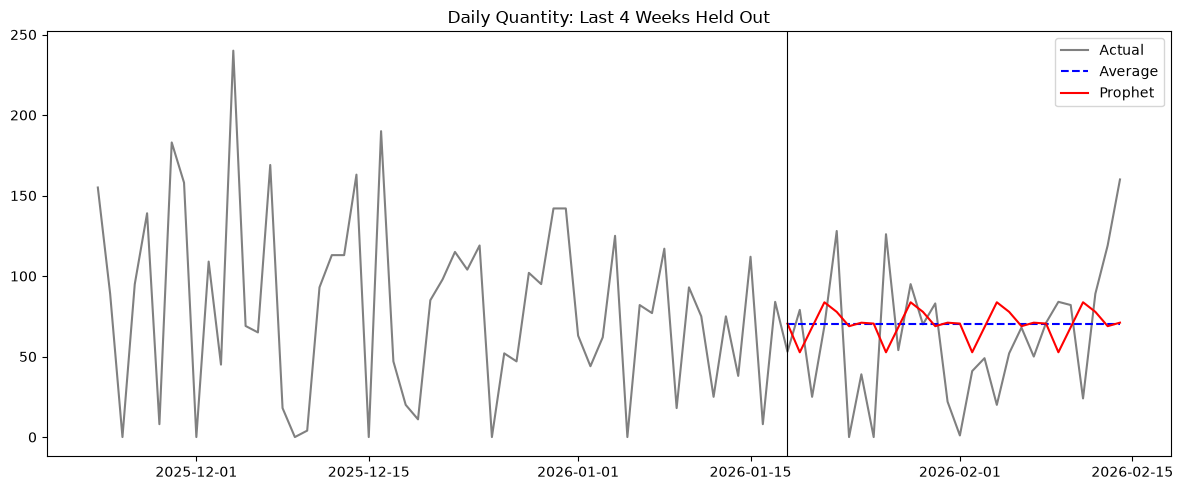

In [5]:
recent = df_Quantity.iloc[-HORIZON * 3:]  #show 8 weeks of history before the holdout
plt.figure(figsize=(12, 5))
plt.plot(recent['Transaction_Date'], recent['Quantity'], label='Actual', color='grey')
plt.plot(test['Transaction_Date'], holdout['Average'], label='Average', color='blue', linestyle='--')
plt.plot(test['Transaction_Date'], holdout['Prophet'], label='Prophet', color='red')
plt.axvline(test['Transaction_Date'].iloc[0], color='black', linewidth=0.8)
plt.title('Daily Quantity: Last 4 Weeks Held Out')
plt.legend()
plt.tight_layout()
plt.savefig('../reports/figures/holdout_quantity.png', dpi=120)
plt.show()

**Holdout result:** Prophet doesn't beat the plain average. Its forecast is a gentle weekly wiggle around roughly the same level as the average, while the actual days swing far more widely in both directions. One 4-week window is a small test, though, so the next section repeats it over several windows.

## Rolling backtest

Repeat the holdout 6 times, each time training on everything before a 4-week window and forecasting that window. This covers the last 24 weeks of the year and gives a fairer comparison than a single test.

In [6]:
def backtest(series, col, folds=6, horizon=HORIZON):
    rows = []
    for fold in range(folds, 0, -1):
        end = len(series) - (fold - 1) * horizon
        train, test = series.iloc[:end - horizon], series.iloc[end - horizon:end]
        for name, pred in forecasts(train, test, col).items():
            rows.append({'Test start': test['Transaction_Date'].iloc[0].date(), 'Model': name,
                         'MAE': np.abs(test[col].to_numpy() - pred).mean()})
    return pd.DataFrame(rows).pivot(index='Test start', columns='Model', values='MAE')

bt_quantity = backtest(df_Quantity, 'Quantity')
bt_quantity.round(1)

Model,Average,Last 8 weeks average,Prophet,Prophet (outliers capped),Weekday average
Test start,,,,,
2025-08-31,43.0,42.8,40.5,40.5,41.3
2025-09-28,37.4,36.4,39.6,39.3,40.7
2025-10-26,37.2,36.9,35.7,35.5,36.5
2025-11-23,59.7,60.3,62.4,62.2,61.5
2025-12-21,35.0,34.3,35.9,36.1,35.8
2026-01-18,32.2,35.1,34.3,34.2,34.3


In [7]:
bt_quantity.mean().sort_values().round(1)  #average MAE across the 6 windows

Model
Average                      40.7
Last 8 weeks average         41.0
Prophet (outliers capped)    41.3
Prophet                      41.4
Weekday average              41.7
dtype: float64

In [8]:
bt_sales = backtest(df_Sales, 'Total_Amount')
bt_sales.mean().sort_values().round(0)  #average MAE in dollars across the 6 windows

Model
Last 8 weeks average         115751.0
Prophet (outliers capped)    116085.0
Average                      116218.0
Prophet                      116394.0
Weekday average              117858.0
dtype: float64

**Backtest result:** across all 6 windows, every model lands within about 2% of the plain average, for both quantity and sales, and none wins consistently. The weekday differences seen in the training data don't carry over into the following weeks, so they look like noise rather than a real weekly pattern. There's also no trend for Prophet to pick up.

**Outlier decision: keep them.** Capping the 4 very high days changes the average error by less than 0.5%, so they aren't distorting the forecast. Since they're real sales, there's no reason to alter them.

With roughly 3 transactions a day, the daily totals are mostly random. The best a model can do day-to-day is predict the average.

## Weekly totals

Individual days are too noisy to forecast, but adding them up into weeks smooths out a lot of that noise. Weeks run Sunday to Saturday; the first, partial week (only 15 Feb 2025) is dropped.

In [9]:
def weekly_totals(series, col):
    weekly = series.set_index('Transaction_Date')[col].resample('W-SAT').agg(['sum', 'count'])
    return weekly[weekly['count'] == 7]['sum'].rename(col).rename_axis('Week_Ending').reset_index()  #full weeks only

weekly_quantity = weekly_totals(df_Quantity, 'Quantity')
weekly_sales = weekly_totals(df_Sales, 'Total_Amount')

for name, daily, weekly, col in [('Quantity', df_Quantity, weekly_quantity, 'Quantity'),
                                 ('Sales', df_Sales, weekly_sales, 'Total_Amount')]:
    daily_spread = daily[col].std() / daily[col].mean()
    weekly_spread = weekly[col].std() / weekly[col].mean()
    print(f'{name}: {len(weekly)} weeks | typical swing: daily {daily_spread:.0%}, weekly {weekly_spread:.0%}')

Quantity: 52 weeks | typical swing: daily 72%, weekly 25%
Sales: 52 weeks | typical swing: daily 82%, weekly 32%


In [10]:
def weekly_backtest(weekly, col, folds=6, horizon=4):
    rows = []
    for fold in range(folds, 0, -1):
        end = len(weekly) - (fold - 1) * horizon
        train, test = weekly.iloc[:end - horizon], weekly.iloc[end - horizon:end]
        actual = test[col].to_numpy()
        preds = {
            'Average': np.full(horizon, train[col].mean()),
            'Last 8 weeks average': np.full(horizon, train[col].iloc[-8:].mean()),
            'Prophet': prophet_forecast(train.rename(columns={'Week_Ending': 'Transaction_Date'}), col,
                                        horizon, freq='W-SAT', weekly=False),
        }
        for name, pred in preds.items():
            rows.append({'Model': name, 'Error %': np.abs(actual - pred).mean() / actual.mean()})
    return pd.DataFrame(rows).groupby('Model')['Error %'].mean().sort_values()

pd.DataFrame({'Quantity': weekly_backtest(weekly_quantity, 'Quantity'),
              'Sales': weekly_backtest(weekly_sales, 'Total_Amount')}).map('{:.1%}'.format)

,Quantity,Sales
Model,,
Average,21.6%,29.3%
Prophet,22.5%,30.1%
Last 8 weeks average,23.3%,31.4%


**Weekly result:** week to week, the totals swing far less than individual days, which makes weekly forecasts much more useful. The plain average is still the best model, missing a typical week by about 22% for quantity and 29% for sales. Prophet and the recent-weeks average do slightly worse.

## Forecast for the next 4 weeks

Because nothing beats the average, the forecast is the average weekly total. The range shows where 8 out of 10 past weeks fell (10th to 90th percentile), which gives an honest sense of how far a single week can land from the forecast.

In [11]:
weeks_ahead = pd.date_range(weekly_quantity['Week_Ending'].max() + pd.Timedelta(weeks=1), periods=4, freq='W-SAT')

def weekly_forecast(weekly, col):
    low, high = weekly[col].quantile([0.1, 0.9])
    return weekly[col].mean(), low, high

qty_mean, qty_low, qty_high = weekly_forecast(weekly_quantity, 'Quantity')
sales_mean, sales_low, sales_high = weekly_forecast(weekly_sales, 'Total_Amount')

forecast = pd.DataFrame({
    'Week_Ending': weeks_ahead.date,
    'Quantity': round(qty_mean),
    'Quantity range': f'{qty_low:,.0f} to {qty_high:,.0f}',
    'Sales ($)': f'{sales_mean:,.0f}',
    'Sales range ($)': f'{sales_low:,.0f} to {sales_high:,.0f}',
})
forecast

,Week_Ending,Quantity,Quantity range,Sales ($),Sales range ($)
0,2026-02-21,486,314 to 655,"1,224,487","725,765 to 1,675,408"
1,2026-02-28,486,314 to 655,"1,224,487","725,765 to 1,675,408"
2,2026-03-07,486,314 to 655,"1,224,487","725,765 to 1,675,408"
3,2026-03-14,486,314 to 655,"1,224,487","725,765 to 1,675,408"


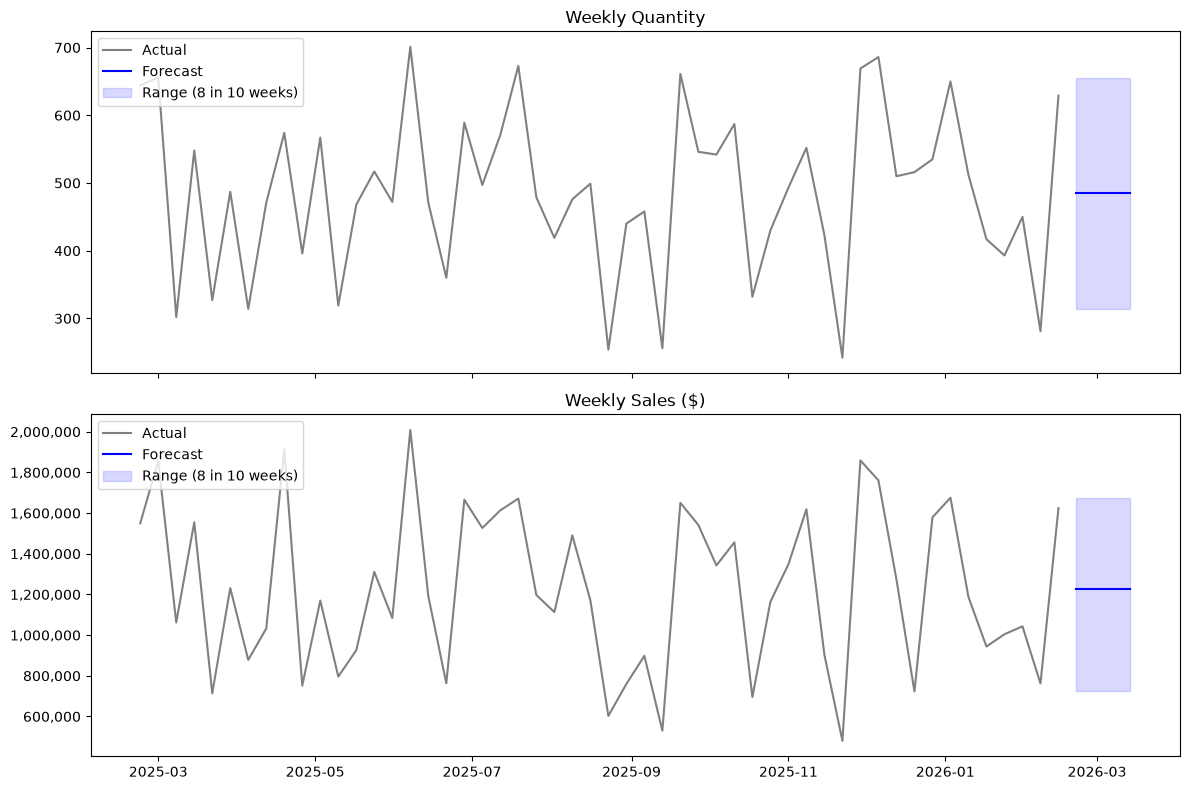

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for ax, weekly, col, (mean, low, high), title in [
        (axes[0], weekly_quantity, 'Quantity', (qty_mean, qty_low, qty_high), 'Weekly Quantity'),
        (axes[1], weekly_sales, 'Total_Amount', (sales_mean, sales_low, sales_high), 'Weekly Sales ($)')]:
    ax.plot(weekly['Week_Ending'], weekly[col], label='Actual', color='grey')
    ax.plot(weeks_ahead, [mean] * 4, label='Forecast', color='blue')
    ax.fill_between(weeks_ahead, low, high, color='blue', alpha=0.15, label='Range (8 in 10 weeks)')
    ax.set_title(title)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f'{value:,.0f}'))  #full numbers, not 1e6
    ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig('../reports/figures/weekly_forecast.png', dpi=120)
plt.show()

## Conclusion

- **Forecast:** about **486 units** and **$1.22M in sales per week** for the 4 weeks ending 21 Feb to 14 Mar 2026. In 8 out of 10 past weeks, quantity was between 314 and 655 units and sales between $726K and $1.68M, so expect individual weeks to land anywhere in that range.
- **Why the average:** Prophet, weekday patterns and recent-weeks averages were all tested on 6 separate 4-week windows and none of them beat the plain average. The data shows no trend and no reliable weekly pattern, just random variation from week to week.
- **Outliers:** kept as they are. Capping them made no meaningful difference.
- **What would improve it:** past totals alone can't predict more precisely than this. A second year of data would show whether there's a yearly cycle, and information about upcoming orders or customers would give the forecast something to work with beyond history.